# PromoSmart: simulador de promociones y descuentos para comercio electrónico

**Curso:** ADMI 1301 – Introducción a la Programación · Proyecto final (Opción A: aplicación sencilla en Python)

**Integrantes:** Juan David Bayer Jaime, Simón Camacho Hernández, Samuel Escandón, Lucas Roldán

---

### ¿Qué problema resolvemos?
Muchas tiendas pequeñas en línea ponen descuentos "a ojo". A veces venden más unidades, pero **ganan menos plata** o **se quedan sin inventario**.

### ¿Qué hace PromoSmart?
1. Le pide al usuario unos datos básicos: precio, costo, inventario y ventas esperadas.
2. Aplica tres reglas de negocio:
   - **Descuento según el tipo de cliente** (Nuevo, Frecuente, VIP).
   - **Descuento por volumen** (si el cliente compra muchas unidades).
   - **Restricción de inventario** (no se puede vender más de lo que hay en bodega).
3. Compara varios escenarios (**sin promoción** vs. **con promociones**) en una **tabla** y en **gráficos**, para ver cuál deja **más ganancia**.

### ¿Cómo se usa?
- Ejecute las celdas en orden, de arriba hacia abajo (menú *Run → Run All* o *Entorno de ejecución → Ejecutar todas*).
- Por defecto usa datos de ejemplo. Si quiere escribir sus propios datos, cambie `USAR_INPUT = False` por `USAR_INPUT = True` en el **Paso 1**.
- Solo necesita las librerías `pandas` y `matplotlib` (vienen instaladas en Google Colab y Anaconda).


## Paso 0. Importar las librerías
- `pandas` sirve para armar la tabla comparativa (como una hoja de Excel).
- `matplotlib` sirve para hacer los gráficos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Paso 1. Datos del negocio (entradas)
Aquí están los datos que el usuario le da a la aplicación.

- Si `USAR_INPUT` es `False`, el programa usa los **datos de ejemplo** (una tienda en línea que vende un producto de $80.000).
- Si `USAR_INPUT` es `True`, el programa le **pregunta** cada dato. Si deja la respuesta vacía y presiona Enter, usa el valor de ejemplo.

In [2]:
USAR_INPUT = False   # Cambie a True para escribir sus propios datos

# Datos de ejemplo
precio_base = 80000          # precio de venta de 1 unidad (pesos)
costo_unitario = 45000       # lo que le cuesta a la tienda 1 unidad (pesos)
inventario = 1500            # unidades disponibles en bodega
ventas_estimadas = 1000      # unidades que esperamos vender en un mes SIN promoción
costo_campana = 1000000      # lo que cuesta anunciar una promoción (publicidad), en pesos


def pedir_numero(pregunta, valor_por_defecto):
    """Le pregunta un número al usuario. Si no escribe nada, devuelve el valor por defecto."""
    respuesta = input(pregunta + " (Enter = " + str(valor_por_defecto) + "): ")
    if respuesta == "":
        return valor_por_defecto
    else:
        return float(respuesta)


if USAR_INPUT == True:
    precio_base = pedir_numero("Precio de venta por unidad", precio_base)
    costo_unitario = pedir_numero("Costo por unidad", costo_unitario)
    inventario = pedir_numero("Unidades en inventario", inventario)
    ventas_estimadas = pedir_numero("Ventas esperadas sin promoción (unidades)", ventas_estimadas)
    costo_campana = pedir_numero("Costo de anunciar la promoción", costo_campana)

print("Precio de venta:", precio_base)
print("Costo por unidad:", costo_unitario)
print("Ganancia por unidad sin descuento:", precio_base - costo_unitario)
print("Inventario:", inventario, "unidades")
print("Ventas esperadas sin promoción:", ventas_estimadas, "unidades")

Precio de venta: 80000
Costo por unidad: 45000
Ganancia por unidad sin descuento: 35000
Inventario: 1500 unidades
Ventas esperadas sin promoción: 1000 unidades


## Paso 2. Tipos de cliente
Usamos **listas paralelas**: la posición 0 de cada lista es el cliente Nuevo, la 1 el Frecuente y la 2 el VIP.

| Tipo | % de las ventas | Unidades por compra |
|---|---|---|
| Nuevo | 50 % | 1 |
| Frecuente | 35 % | 2 |
| VIP | 15 % | 4 |

*Estos porcentajes son un **supuesto** de ejemplo; cada tienda puede cambiarlos según sus propios datos.*

In [3]:
tipos_cliente = ["Nuevo", "Frecuente", "VIP"]
participacion = [0.50, 0.35, 0.15]      # qué parte de las ventas hace cada tipo (suma 1 = 100 %)
unidades_por_compra = [1, 2, 4]         # cuántas unidades lleva cada cliente en una compra

for i in range(len(tipos_cliente)):
    print(tipos_cliente[i], "->", participacion[i] * 100, "% de las ventas,",
          unidades_por_compra[i], "unidades por compra")

Nuevo -> 50.0 % de las ventas, 1 unidades por compra
Frecuente -> 35.0 % de las ventas, 2 unidades por compra
VIP -> 15.0 % de las ventas, 4 unidades por compra


## Paso 3. Supuesto de comportamiento del cliente
Cuando hay descuento, la gente compra más. Usamos una regla sencilla:

> **Por cada 1 % de descuento, las ventas suben 4 %.**

Ejemplo: con 10 % de descuento, las ventas suben 40 %.

*Este número (4) es un supuesto. En la vida real depende del producto; por eso se puede cambiar aquí.*

In [4]:
sensibilidad = 4   # por cada 1 % de descuento, las ventas suben 4 %

## Paso 4. Reglas de negocio (funciones)
Cada regla es una **función** pequeña. Así el código es más fácil de leer y de explicar.

In [5]:
def descuento_por_tipo(tipo, descuentos):
    """Regla 1: devuelve el descuento según el tipo de cliente.
    'descuentos' es una lista con el descuento de [Nuevo, Frecuente, VIP]."""
    if tipo == "Nuevo":
        return descuentos[0]
    elif tipo == "Frecuente":
        return descuentos[1]
    else:   # VIP
        return descuentos[2]


def descuento_por_volumen(unidades, activar_volumen):
    """Regla 2: si el cliente compra muchas unidades en una compra, le damos un descuento extra."""
    if activar_volumen == False:
        return 0
    if unidades >= 4:
        return 0.10    # 10 % extra si compra 4 o más
    elif unidades >= 2:
        return 0.05    # 5 % extra si compra 2 o 3
    else:
        return 0       # sin descuento extra si compra 1


def limitar_descuento(descuento):
    """Regla de seguridad: el descuento total nunca puede pasar de 40 %."""
    if descuento > 0.40:
        return 0.40
    return descuento


# Probamos las funciones con un ejemplo
print("Descuento para un VIP:", descuento_por_tipo("VIP", [0.05, 0.10, 0.15]))
print("Descuento por comprar 4 unidades:", descuento_por_volumen(4, True))
print("Un descuento de 55 % se limita a:", limitar_descuento(0.55))

Descuento para un VIP: 0.15
Descuento por comprar 4 unidades: 0.1
Un descuento de 55 % se limita a: 0.4


## Paso 5. La función principal: simular un escenario
Esta función hace todos los cálculos de **un** escenario de promoción:

1. Para cada tipo de cliente calcula su descuento (tipo + volumen) y cuántas unidades querría comprar.
2. **Regla 3 (inventario):** si la gente quiere comprar más unidades de las que hay en bodega, solo se vende lo que hay. Se reparte en la misma proporción entre los tipos de cliente.
3. Calcula **ingresos**, **costos** y **ganancia**.

In [6]:
def simular_escenario(nombre, descuentos, activar_volumen, tiene_campana):
    unidades_deseadas = []   # cuántas unidades querría comprar cada tipo
    descuento_final = []     # descuento total que recibe cada tipo

    # 1) Recorremos cada tipo de cliente con un ciclo for
    for i in range(len(tipos_cliente)):
        tipo = tipos_cliente[i]
        d_tipo = descuento_por_tipo(tipo, descuentos)
        d_volumen = descuento_por_volumen(unidades_por_compra[i], activar_volumen)
        d_total = limitar_descuento(d_tipo + d_volumen)

        # unidades base de este tipo y aumento por el descuento
        unidades_base = ventas_estimadas * participacion[i]
        unidades = unidades_base * (1 + sensibilidad * d_total)

        unidades_deseadas.append(unidades)
        descuento_final.append(d_total)

    # 2) Regla de inventario
    demanda_total = sum(unidades_deseadas)
    if demanda_total > inventario:
        factor = inventario / demanda_total       # ej. 0.9 = solo alcanza para el 90 %
        alerta = "Se agota el inventario"
    else:
        factor = 1
        alerta = "Inventario suficiente"

    # 3) Ingresos y costos
    ingresos = 0
    unidades_vendidas = 0
    for i in range(len(tipos_cliente)):
        vendidas = unidades_deseadas[i] * factor
        precio_con_descuento = precio_base * (1 - descuento_final[i])
        ingresos = ingresos + vendidas * precio_con_descuento
        unidades_vendidas = unidades_vendidas + vendidas

    costos = unidades_vendidas * costo_unitario
    if tiene_campana == True:
        costos = costos + costo_campana

    ganancia = ingresos - costos
    margen = ganancia / ingresos * 100    # qué % de lo que entra es ganancia

    # Devolvemos un diccionario con los resultados del escenario
    return {
        "Escenario": nombre,
        "Unidades vendidas": round(unidades_vendidas),
        "Demanda (unidades)": round(demanda_total),
        "Ingresos": round(ingresos),
        "Costos": round(costos),
        "Ganancia": round(ganancia),
        "Margen (%)": round(margen, 1),
        "Inventario": alerta,
    }

## Paso 6. Definir los escenarios a comparar
Cada escenario dice qué descuento recibe cada tipo de cliente `[Nuevo, Frecuente, VIP]` y si se activa el descuento por volumen.

| Escenario | Nuevo | Frecuente | VIP | Volumen |
|---|---|---|---|---|
| Sin promoción | 0 % | 0 % | 0 % | No |
| Promo suave | 5 % | 5 % | 10 % | No |
| Promo por cliente | 10 % | 5 % | 15 % | No |
| Promo cliente + volumen | 10 % | 5 % | 15 % | Sí |
| Promo agresiva | 25 % | 25 % | 30 % | Sí |

In [7]:
escenarios = [
    ["Sin promoción",           [0.00, 0.00, 0.00], False, False],
    ["Promo suave",             [0.05, 0.05, 0.10], False, True],
    ["Promo por cliente",       [0.10, 0.05, 0.15], False, True],
    ["Promo cliente + volumen", [0.10, 0.05, 0.15], True,  True],
    ["Promo agresiva",          [0.25, 0.25, 0.30], True,  True],
]

resultados = []
for esc in escenarios:
    resultado = simular_escenario(esc[0], esc[1], esc[2], esc[3])
    resultados.append(resultado)

print("Se simularon", len(resultados), "escenarios.")

Se simularon 5 escenarios.


## Paso 7. Tabla comparativa (Tabla 1)
Convertimos la lista de resultados en una tabla de `pandas`.

In [8]:
tabla = pd.DataFrame(resultados)

# Comparamos cada escenario contra "Sin promoción"
ganancia_sin_promo = tabla["Ganancia"][0]
tabla["Diferencia vs. sin promo"] = tabla["Ganancia"] - ganancia_sin_promo

print("Tabla 1. Comparación de escenarios de promoción (cifras en pesos colombianos)")
tabla

Tabla 1. Comparación de escenarios de promoción (cifras en pesos colombianos)


,Escenario,Unidades vendidas,Demanda (unidades),Ingresos,Costos,Ganancia,Margen (%),Inventario,Diferencia vs. sin promo
0,Sin promoción,1000,1000,80000000,45000000,35000000,43.8,Inventario suficiente,0
1,Promo suave,1230,1230,92640000,56350000,36290000,39.2,Inventario suficiente,1290000
2,Promo por cliente,1360,1360,98640000,62200000,36440000,36.9,Inventario suficiente,1440000
3,Promo cliente + volumen,1490,1490,103680000,68050000,35630000,34.4,Inventario suficiente,630000
4,Promo agresiva,1500,2160,84611111,68500000,16111111,19.0,Se agota el inventario,-18888889


## Paso 8. Recomendación automática
El programa busca el escenario con la **ganancia más alta** y lo recomienda.

In [9]:
mejor_fila = tabla["Ganancia"].idxmax()        # posición de la ganancia más alta
mejor = tabla.loc[mejor_fila]

print("RECOMENDACIÓN DE PROMOSMART")
print("---------------------------")
print("El mejor escenario es:", mejor["Escenario"])
print("Ganancia esperada: $", format(mejor["Ganancia"], ","))
if mejor["Escenario"] == "Sin promoción":
    print("Con estos datos, ninguna promoción mejora la ganancia. Es mejor no hacer descuentos.")
else:
    print("Frente a no hacer promoción gana $", format(mejor["Diferencia vs. sin promo"], ","), "más")
print()

# Advertencias sencillas
for i in range(len(tabla)):
    if tabla["Diferencia vs. sin promo"][i] < 0:
        print("Ojo:", tabla["Escenario"][i], "vende más unidades pero deja MENOS ganancia que no hacer nada.")
    if tabla["Inventario"][i] == "Se agota el inventario":
        print("Ojo:", tabla["Escenario"][i], "agota el inventario: hay clientes que se quedan sin producto.")

RECOMENDACIÓN DE PROMOSMART
---------------------------
El mejor escenario es: Promo por cliente
Ganancia esperada: $ 36,440,000
Frente a no hacer promoción gana $ 1,440,000 más

Ojo: Promo agresiva vende más unidades pero deja MENOS ganancia que no hacer nada.
Ojo: Promo agresiva agota el inventario: hay clientes que se quedan sin producto.


## Paso 9. Gráfico 1: ganancia por escenario
La barra verde es el escenario recomendado. La línea punteada es la ganancia **sin promoción**: lo que esté por debajo de esa línea es peor que no hacer nada.

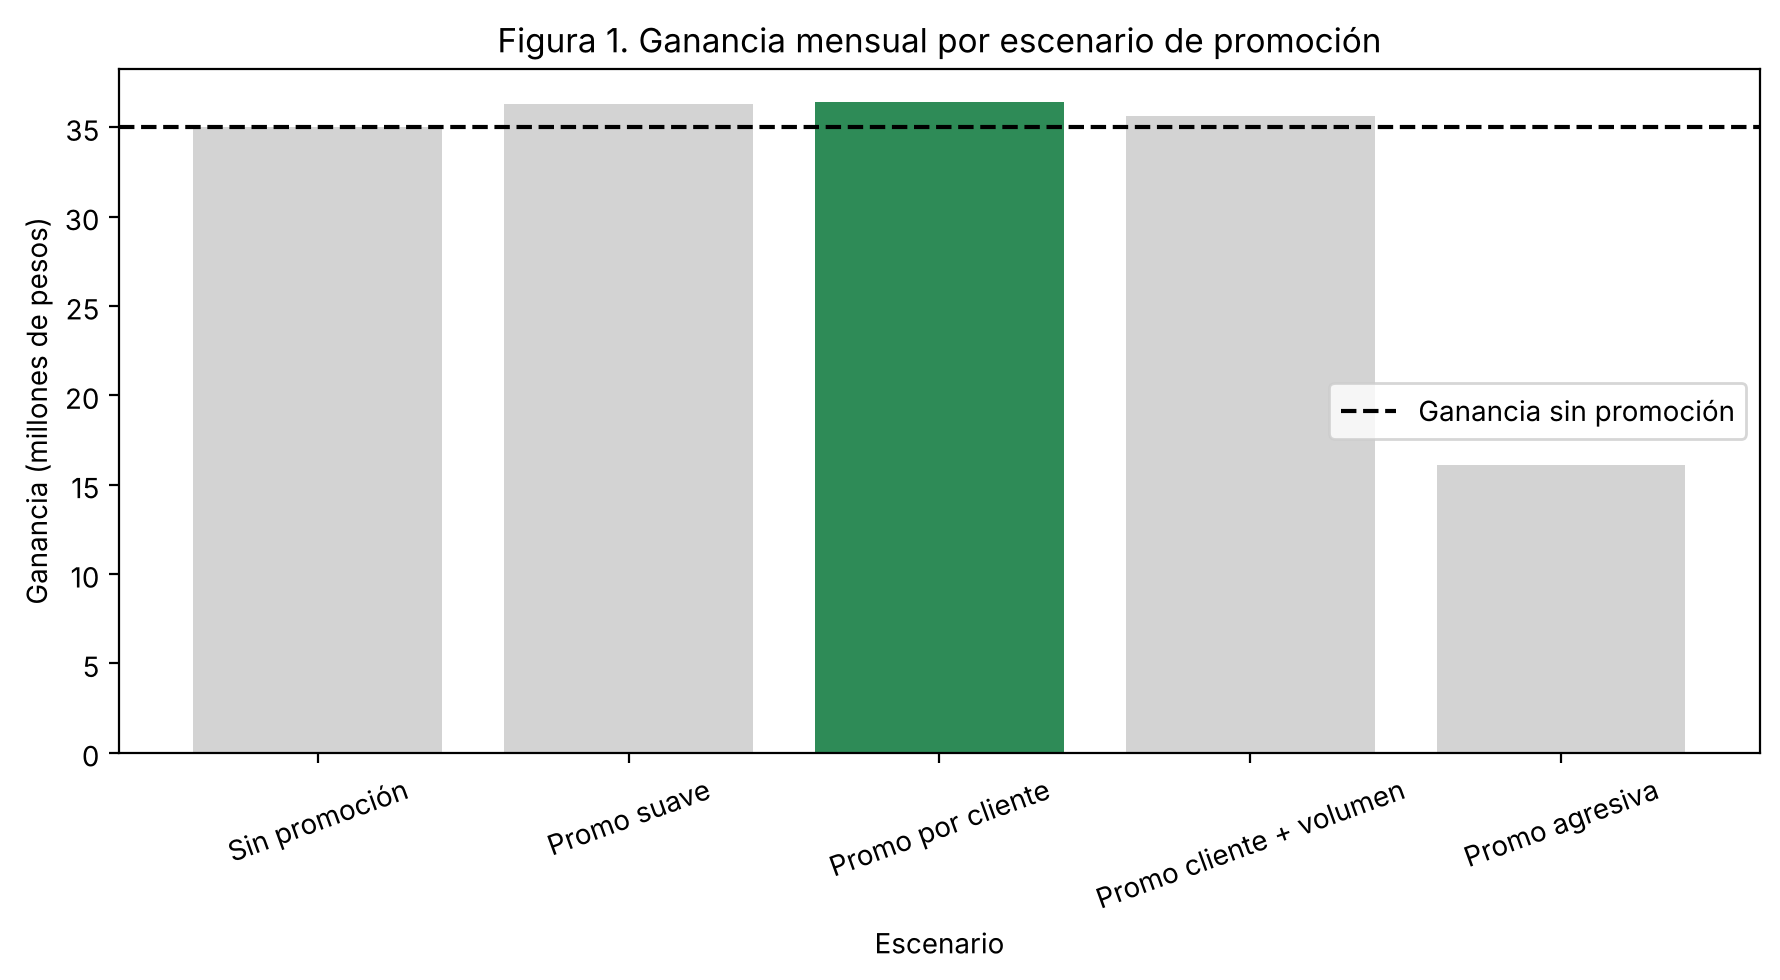

In [10]:
colores = []
for i in range(len(tabla)):
    if i == mejor_fila:
        colores.append("seagreen")
    else:
        colores.append("lightgray")

plt.figure(figsize=(9, 5))
plt.bar(tabla["Escenario"], tabla["Ganancia"] / 1000000, color=colores)
plt.axhline(ganancia_sin_promo / 1000000, color="black", linestyle="--", label="Ganancia sin promoción")
plt.title("Figura 1. Ganancia mensual por escenario de promoción")
plt.ylabel("Ganancia (millones de pesos)")
plt.xlabel("Escenario")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

## Paso 10. Gráfico 2: ¿cuánto descuento conviene dar?
Probamos descuentos iguales para todos los clientes, desde 0 % hasta 40 %, y miramos qué pasa con las **unidades vendidas** y la **ganancia**. Así se ve que vender más no siempre significa ganar más.

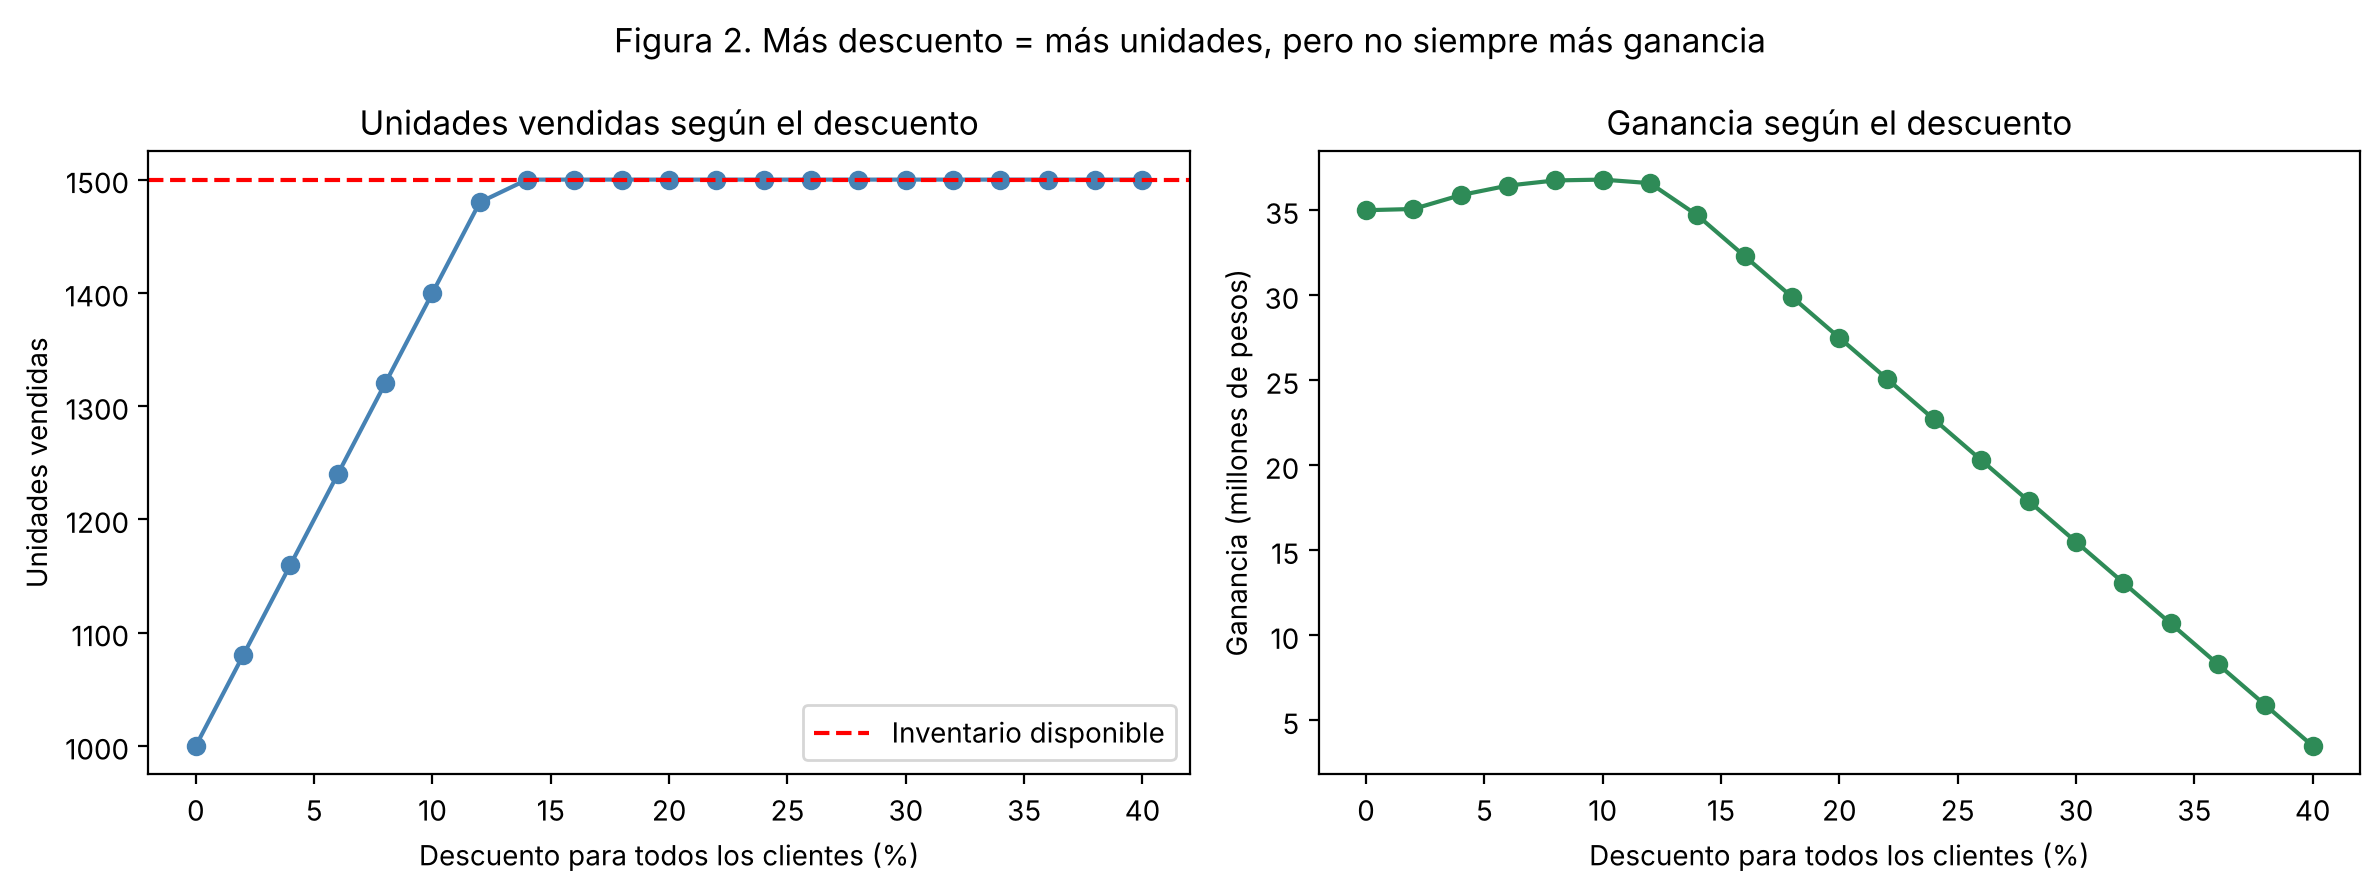

Con descuento igual para todos, la ganancia más alta se logra con 10 % de descuento.


In [11]:
lista_descuentos = []
lista_ganancias = []
lista_unidades = []

for porcentaje in range(0, 41, 2):      # 0, 2, 4, ..., 40
    d = porcentaje / 100
    if porcentaje == 0:
        campana = False
    else:
        campana = True
    r = simular_escenario("Prueba", [d, d, d], False, campana)
    lista_descuentos.append(porcentaje)
    lista_ganancias.append(r["Ganancia"] / 1000000)
    lista_unidades.append(r["Unidades vendidas"])

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

ejes[0].plot(lista_descuentos, lista_unidades, marker="o", color="steelblue")
ejes[0].axhline(inventario, color="red", linestyle="--", label="Inventario disponible")
ejes[0].set_title("Unidades vendidas según el descuento")
ejes[0].set_xlabel("Descuento para todos los clientes (%)")
ejes[0].set_ylabel("Unidades vendidas")
ejes[0].legend()

ejes[1].plot(lista_descuentos, lista_ganancias, marker="o", color="seagreen")
ejes[1].set_title("Ganancia según el descuento")
ejes[1].set_xlabel("Descuento para todos los clientes (%)")
ejes[1].set_ylabel("Ganancia (millones de pesos)")

fig.suptitle("Figura 2. Más descuento = más unidades, pero no siempre más ganancia")
plt.tight_layout()
plt.show()

posicion = lista_ganancias.index(max(lista_ganancias))
print("Con descuento igual para todos, la ganancia más alta se logra con", lista_descuentos[posicion], "% de descuento.")

## Paso 11. Conclusiones
- **Vender más no es lo mismo que ganar más.** La promoción agresiva vende más unidades y agota el inventario, pero deja menos ganancia que no hacer promoción, porque cada unidad deja muy poco margen.
- **Los descuentos moderados y dirigidos funcionan mejor.** Con los datos de ejemplo, la mejor opción es la "Promo por cliente" (10 % a Nuevos, 5 % a Frecuentes y 15 % a VIP): gana unos $1,4 millones más al mes que no hacer promoción. La Figura 2 muestra lo mismo: la ganancia sube hasta un descuento de alrededor de 10 % y después cae.
- **Vender lo máximo tampoco es la meta.** La promo "cliente + volumen" vende casi todo el inventario (1.490 unidades), pero gana menos que la promo "por cliente", que vende 1.360.
- **El inventario pone un techo.** Cuando la demanda supera las unidades en bodega, dar más descuento solo regala margen: ya no se pueden vender más unidades.
- **Utilidad:** antes de lanzar una promoción, el gerente de una tienda pequeña puede probar varias opciones en minutos y escoger la que protege su flujo de caja.

### Limitaciones
- La regla "1 % de descuento = 4 % más ventas" es un **supuesto**; en la realidad depende del producto, la temporada y la competencia.
- Los porcentajes de clientes (50 % / 35 % / 15 %) son de ejemplo, no datos reales de una empresa.
- Se simula **un solo producto** y **un mes**; no se tienen en cuenta devoluciones, costos de envío ni lo que pasa con los clientes en meses siguientes.
- Para usarla en una empresa real habría que reemplazar los supuestos con datos históricos de ventas.

## Nota sobre el uso de inteligencia artificial
- **Herramientas usadas:** Claude (Anthropic).
- **Para qué:** ayudar a organizar el código en funciones, escribir comentarios en lenguaje sencillo y revisar errores.
- **Cómo verificamos:** ejecutamos todas las celdas, revisamos a mano los cálculos de un escenario (precio × unidades − costos) y cambiamos los datos de entrada para comprobar que los resultados tuvieran sentido. Todos los integrantes revisamos y podemos explicar cada parte del código.

*(Ajusten esta nota si usaron otras herramientas o la usaron para otras tareas.)*